In [1]:
# STEP 1 - Convert pdf into separate pages
from langchain_community.document_loaders import PyPDFLoader, TextLoader, WebBaseLoader

loader = PyPDFLoader("Artificial-Intelligence.pdf")

pdf_pages = loader.load()
print(f'No of pages: {len(pdf_pages)}')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.


No of pages: 80


In [2]:
# STEP 2 - Convert every page into sub-pages (chunks)
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
    separators=["\n\n", "\n", ",", " "]
)
chunk_documents = splitter.split_documents(pdf_pages)
print(f'No of chunks: {len(chunk_documents)}')

No of chunks: 344


In [3]:
# STEP 3 - Convert every chunk into vectors.
from langchain_ollama import OllamaEmbeddings
from langchain_community.vectorstores import FAISS

embedding_model = OllamaEmbeddings(model="nomic-embed-text")
print('Embedding model is ready')

faiss_vector_store = FAISS.from_documents(chunk_documents, embedding_model)
faiss_vector_store.save_local("faiss-ai-book")
print('FAISS Vector store created')

Embedding model is ready
FAISS Vector store created


In [41]:
# STEP 4: Build Retrieval Chain

from langchain_core.prompts import PromptTemplate
from langchain_classic.chains import RetrievalQA
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print("Model is ready")

USER_PROMPT_TEMPLATE = """Use the following pieces of the context to answer user's question.
If you don't know the answer, just say you don't know, don't try to make up the answer.
------------------------
{context}
Question: {question}
"""

USER_PROMPT = PromptTemplate(
    template=USER_PROMPT_TEMPLATE,
    input_variables=["context", "question"]
)
retriever = faiss_vector_store.as_retriever()
qa_chain = RetrievalQA.from_chain_type(
    model,
    chain_type="stuff",
    retriever=retriever,
    return_source_documents=True,
    chain_type_kwargs={"prompt": USER_PROMPT}
)
print(qa_chain)
print('Retrieval chain is built successfully...')

Model is ready
verbose=False combine_documents_chain=StuffDocumentsChain(verbose=False, llm_chain=LLMChain(verbose=False, prompt=PromptTemplate(input_variables=['context', 'question'], input_types={}, partial_variables={}, template="Use the following pieces of the context to answer user's question.\nIf you don't know the answer, just say you don't know, don't try to make up the answer.\n------------------------\n{context}\nQuestion: {question}\n"), llm=ChatOllama(metadata={'lc_versions': {'langchain-core': '1.4.8', 'langchain': '1.3.0'}}, output_version=None, model='gpt-oss:120b-cloud'), output_parser=StrOutputParser(), llm_kwargs={}), document_prompt=PromptTemplate(input_variables=['page_content'], input_types={}, partial_variables={}, template='{page_content}'), document_variable_name='context') return_source_documents=True retriever=VectorStoreRetriever(tags=['FAISS', 'OllamaEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x000002575AE624E0>, search

In [33]:
response = qa_chain.invoke("What is an Artificial Intelligence?")
response

{'query': 'What is an Artificial Intelligence?',
 'result': 'Artificial Intelligence is the theory and development of computer systems that can perform tasks which normally require human intelligence. In other words, it is creating machines that can replicate or emulate the kind of thinking, learning, and problem‑solving that humans do.',
 'source_documents': [Document(id='8232c372-3514-4a93-aaec-34ab3b4f1ba0', metadata={'producer': 'Pdftools SDK', 'creator': 'PyPDF', 'creationdate': '', 'moddate': '2024-09-19T22:02:58+00:00', 'source': 'Artificial-Intelligence.pdf', 'total_pages': 80, 'page': 0, 'page_label': '1'}, page_content='ARTIFICIAL \nINTELLIGENCE'),
  Document(id='4b5b95c9-d2e3-41c8-beed-17015d880352', metadata={'producer': 'Pdftools SDK', 'creator': 'PyPDF', 'creationdate': '', 'moddate': '2024-09-19T22:02:58+00:00', 'source': 'Artificial-Intelligence.pdf', 'total_pages': 80, 'page': 7, 'page_label': '8'}, page_content='copy of something natural.\nARTIFICIAL INTELLIGENCE \nTh

In [42]:
# STEP-1: Define the state
from typing import List, TypedDict, Annotated
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from langchain_core.documents import Document

class RAGState(TypedDict):
    question: str
    documents: List[Document]
    answer: str

print('Graph RAG state is ready..')

Graph RAG state is ready..


In [47]:
# STEP-2 - Define the nodes
def retrieve_documents(state: RAGState):
    question = state['question']
    documents = retriever.invoke(question)
    print(f'Retrieved documents: {documents}')
    return {'documents': documents}

def generate_answer(state: RAGState):
    question = state['question']
    documents = state['documents']

    context = "\n\n".join(
        document.page_content for document in documents
    )
    messages = USER_PROMPT.invoke({
        "context": context,
        "question": question
    })
    print(f'Generated messages: {messages}')
    response = model.invoke(messages)
    print(f'Model response: {response}')
    return {
        "answer": response.content
    }

print('RAG nodes are ready..')


RAG nodes are ready..


RAG Graph is ready...


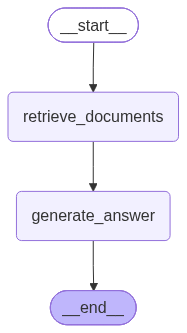

In [48]:
# STEP-3: Add edges and build the graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(RAGState)

# Node registration
graph_builder.add_node("retrieve_documents", retrieve_documents)
graph_builder.add_node("generate_answer", generate_answer)

# Add edges
graph_builder.add_edge(START, "retrieve_documents")
graph_builder.add_edge("retrieve_documents", "generate_answer")
graph_builder.add_edge("generate_answer", END)

graph = graph_builder.compile()
print('RAG Graph is ready...')
graph

In [49]:
response = graph.invoke({
    "question": "What is an Artificial Intelligence?"
})
response

Retrieved documents: [Document(id='8232c372-3514-4a93-aaec-34ab3b4f1ba0', metadata={'producer': 'Pdftools SDK', 'creator': 'PyPDF', 'creationdate': '', 'moddate': '2024-09-19T22:02:58+00:00', 'source': 'Artificial-Intelligence.pdf', 'total_pages': 80, 'page': 0, 'page_label': '1'}, page_content='ARTIFICIAL \nINTELLIGENCE'), Document(id='4b5b95c9-d2e3-41c8-beed-17015d880352', metadata={'producer': 'Pdftools SDK', 'creator': 'PyPDF', 'creationdate': '', 'moddate': '2024-09-19T22:02:58+00:00', 'source': 'Artificial-Intelligence.pdf', 'total_pages': 80, 'page': 7, 'page_label': '8'}, page_content='copy of something natural.\nARTIFICIAL INTELLIGENCE \nThe theory and development of \ncomputer systems able to per-\nform tasks that normally require \nhuman intelligence.\nAUTOMATION The technique, \nmethod, or system of controlling \na process by reducing human \nintervention to a minimum.'), Document(id='92004e8f-5d9c-474a-9001-ba8a2e5a2e7d', metadata={'producer': 'Pdftools SDK', 'creator': 'P

{'question': 'What is an Artificial Intelligence?',
 'documents': [Document(id='8232c372-3514-4a93-aaec-34ab3b4f1ba0', metadata={'producer': 'Pdftools SDK', 'creator': 'PyPDF', 'creationdate': '', 'moddate': '2024-09-19T22:02:58+00:00', 'source': 'Artificial-Intelligence.pdf', 'total_pages': 80, 'page': 0, 'page_label': '1'}, page_content='ARTIFICIAL \nINTELLIGENCE'),
  Document(id='4b5b95c9-d2e3-41c8-beed-17015d880352', metadata={'producer': 'Pdftools SDK', 'creator': 'PyPDF', 'creationdate': '', 'moddate': '2024-09-19T22:02:58+00:00', 'source': 'Artificial-Intelligence.pdf', 'total_pages': 80, 'page': 7, 'page_label': '8'}, page_content='copy of something natural.\nARTIFICIAL INTELLIGENCE \nThe theory and development of \ncomputer systems able to per-\nform tasks that normally require \nhuman intelligence.\nAUTOMATION The technique, \nmethod, or system of controlling \na process by reducing human \nintervention to a minimum.'),
  Document(id='92004e8f-5d9c-474a-9001-ba8a2e5a2e7d', me